<a href="https://colab.research.google.com/github/taniapanjaitan7-hub/Machine-Learning-Colab/blob/main/Copy_of_Deteksi_Umur_Pakcoy_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import os

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))
print("Lokasi kerja:", os.getcwd())

TensorFlow: 2.21.0
GPU tersedia: []
Lokasi kerja: /content


In [ ]:
!git clone https://github.com/SupratikSeth/PlantVillage-Classification-Using-MobileNetV2.git

Cloning into 'PlantVillage-Classification-Using-MobileNetV2'...
remote: Enumerating objects: 20721, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 20721 (delta 3), reused 11 (delta 2), pack-reused 20708 (from 1)
Receiving objects: 100% (20721/20721), 350.07 MiB | 30.24 MiB/s, done.
Resolving deltas: 100% (50/50), done.
Updating files: 100% (20648/20648), done.


In [ ]:
!ls /content/PlantVillage-Classification-Using-MobileNetV2

Datasets		plant_village_image_classification_mobilenet_v2.ipynb
fine_tuned_model.keras	README.md
Images			requirements.txt


In [ ]:
import os

base_path = "/content/PlantVillage-Classification-Using-MobileNetV2"

for folder in ["Datasets", "Images"]:
    folder_path = os.path.join(base_path, folder)
    print(f"\n=== {folder} ===")

    if os.path.exists(folder_path):
        isi = os.listdir(folder_path)
        for nama in isi[:15]:
            print(nama)
        print("Jumlah item:", len(isi))
    else:
        print("Folder tidak ditemukan.")


=== Datasets ===
PlantVillageDataset
Jumlah item: 1

=== Images ===
Tomato Early Blight.jpg
Tomato Leaf Mold.jpg
Pepper Bell Healthy.png
Potato Late Blight.jpg
Jumlah item: 4


In [ ]:
import os

dataset_path = "/content/dataset_pakcoy"

kelas = [
    "2_minggu",
    "3_minggu",
    "4_minggu",
    "siap_panen"
]

for nama_kelas in kelas:
    folder = os.path.join(dataset_path, nama_kelas)
    os.makedirs(folder, exist_ok=True)

print("Folder dataset berhasil disiapkan!")

for nama_kelas in kelas:
    folder = os.path.join(dataset_path, nama_kelas)
    print(nama_kelas, ":", len(os.listdir(folder)), "gambar")

Folder dataset berhasil disiapkan!
2_minggu : 0 gambar
3_minggu : 0 gambar
4_minggu : 0 gambar
siap_panen : 0 gambar


In [ ]:
import zipfile
import os

zip_path = "/content/dataset_pakcoy_demo.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print(os.listdir("/content/dataset_pakcoy_demo"))

Dataset berhasil diekstrak!
['README.txt', '2_minggu', '4_minggu', '3_minggu', 'siap_panen']


In [ ]:
import os

dataset_path = "/content/dataset_pakcoy_demo"

kelas = [
    "2_minggu",
    "3_minggu",
    "4_minggu",
    "siap_panen"
]

for nama_kelas in kelas:
    folder = os.path.join(dataset_path, nama_kelas)
    gambar = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(nama_kelas, "=", len(gambar), "gambar")

2_minggu = 8 gambar
3_minggu = 8 gambar
4_minggu = 8 gambar
siap_panen = 8 gambar


In [ ]:
import tensorflow as tf

dataset_path = "/content/dataset_pakcoy_demo"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224, 224),
    batch_size=8,
    label_mode="int",
    shuffle=True,
    seed=42
)

print("Nama kelas:", train_ds.class_names)

Found 32 files belonging to 4 classes.
Nama kelas: ['2_minggu', '3_minggu', '4_minggu', 'siap_panen']


In [ ]:
import tensorflow as tf

dataset_path = "/content/dataset_pakcoy_demo"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.25,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=4,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.25,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=4,
    label_mode="int"
)

print("Kelas:", train_ds.class_names)
print("Dataset latihan dan validasi berhasil disiapkan.")

Found 32 files belonging to 4 classes.
Using 24 files for training.
Found 32 files belonging to 4 classes.
Using 8 files for validation.
Kelas: ['2_minggu', '3_minggu', '4_minggu', 'siap_panen']
Dataset latihan dan validasi berhasil disiapkan.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Memuat MobileNetV2 dengan bobot pralatih ImageNet
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Membekukan lapisan dasar
base_model.trainable = False

print("MobileNetV2 berhasil dimuat!")
print("Jumlah lapisan:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 berhasil dimuat!
Jumlah lapisan: 154


In [ ]:
from tensorflow.keras import layers, models

num_classes = 4

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Persiapan gambar untuk MobileNetV2
    layers.Rescaling(1./127.5, offset=-1),

    # Ekstraksi fitur gambar
    base_model,

    # Lapisan klasifikasi
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Melatih model untuk uji coba alur program
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

print("Pelatihan selesai!")

Epoch 1/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 504ms/step - accuracy: 0.3750 - loss: 1.4866 - val_accuracy: 0.3750 - val_loss: 1.1141
Epoch 2/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 213ms/step - accuracy: 0.4583 - loss: 1.0025 - val_accuracy: 0.5000 - val_loss: 0.8836
Epoch 3/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 204ms/step - accuracy: 0.6667 - loss: 0.7819 - val_accuracy: 0.8750 - val_loss: 0.7451
Epoch 4/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 205ms/step - accuracy: 0.7500 - loss: 0.6429 - val_accuracy: 0.7500 - val_loss: 0.6651
Epoch 5/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 213ms/step - accuracy: 0.8750 - loss: 0.5202 - val_accuracy: 0.7500 - val_loss: 0.5705
Pelatihan selesai!


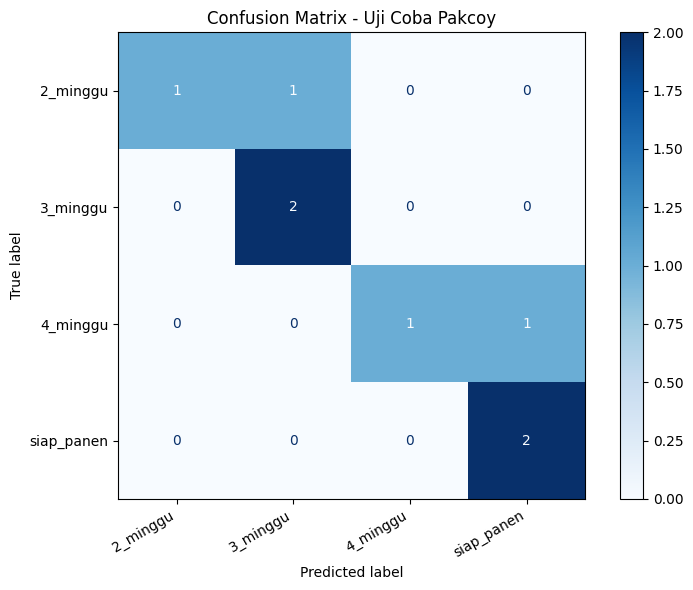

              precision    recall  f1-score   support

    2_minggu       1.00      0.50      0.67         2
    3_minggu       0.67      1.00      0.80         2
    4_minggu       1.00      0.50      0.67         2
  siap_panen       0.67      1.00      0.80         2

    accuracy                           0.75         8
   macro avg       0.83      0.75      0.73         8
weighted avg       0.83      0.75      0.73         8



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

class_names = train_ds.class_names

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
display.plot(ax=ax, cmap="Blues", values_format="d")
plt.xticks(rotation=30, ha="right")
plt.title("Confusion Matrix - Uji Coba Pakcoy")
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
# Simpan model hasil pelatihan
model.save("/content/model_pakcoy_mobilenetv2.keras")

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [ ]:
from google.colab import files

files.download("/content/model_pakcoy_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf

model_path = "/content/model_pakcoy_mobilenetv2.keras"

model_tersimpan = tf.keras.models.load_model(model_path)

print("Model berhasil dimuat kembali!")
print("Bentuk input:", model_tersimpan.input_shape)
print("Bentuk output:", model_tersimpan.output_shape)

Model berhasil dimuat kembali!
Bentuk input: (None, 224, 224, 3)
Bentuk output: (None, 4)


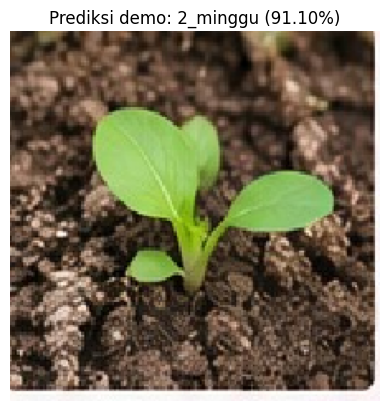

File gambar: pakcoy_08.jpg
Kelas prediksi: 2_minggu
Skor model: 91.10%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

# Ambil satu gambar dari dataset demo
dataset_path = Path("/content/dataset_pakcoy_demo")
class_names = ["2_minggu", "3_minggu", "4_minggu", "siap_panen"]

image_path = next(dataset_path.glob("2_minggu/*.jpg"))

# Baca dan sesuaikan ukuran gambar
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Prediksi menggunakan model yang sudah dimuat
prediksi = model_tersimpan.predict(img_array, verbose=0)[0]

kelas_prediksi = class_names[np.argmax(prediksi)]
skor = float(np.max(prediksi)) * 100

plt.imshow(img)
plt.axis("off")
plt.title(f"Prediksi demo: {kelas_prediksi} ({skor:.2f}%)")
plt.show()

print("File gambar:", image_path.name)
print("Kelas prediksi:", kelas_prediksi)
print(f"Skor model: {skor:.2f}%")

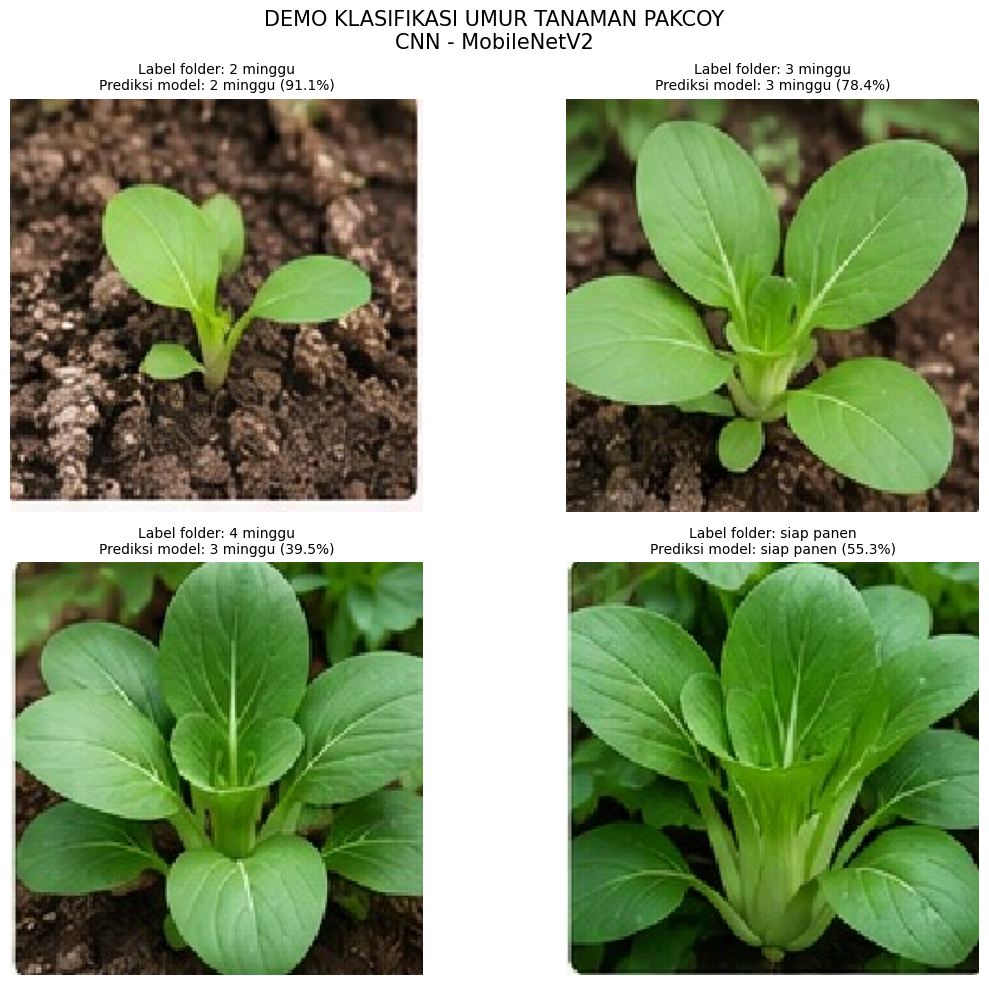

In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Lokasi gambar demo yang sudah dibuat sebelumnya
folder_dataset = Path("/content/dataset_pakcoy_demo")

kelas_pakcoy = [
    "2_minggu",
    "3_minggu",
    "4_minggu",
    "siap_panen"
]

ekstensi_gambar = ["*.jpg", "*.jpeg", "*.png", "*.webp"]

# Memastikan model tersedia
try:
    model_dipakai = model_tersimpan
except NameError:
    model_dipakai = model

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, kelas in enumerate(kelas_pakcoy):
    folder_kelas = folder_dataset / kelas

    daftar_gambar = []
    for ekstensi in ekstensi_gambar:
        daftar_gambar.extend(folder_kelas.glob(ekstensi))

    if not daftar_gambar:
        axes[i].text(
            0.5, 0.5,
            f"Foto belum tersedia\n{kelas}",
            ha="center", va="center"
        )
        axes[i].axis("off")
        continue

    # Ambil satu gambar dari masing-masing kelas
    path_gambar = daftar_gambar[0]
    gambar = tf.keras.utils.load_img(
        path_gambar,
        target_size=(224, 224)
    )

    array_gambar = tf.keras.utils.img_to_array(gambar)
    batch_gambar = np.expand_dims(array_gambar, axis=0)

    # Prediksi model
    hasil = model_dipakai.predict(batch_gambar, verbose=0)[0]
    indeks = int(np.argmax(hasil))
    kelas_prediksi = kelas_pakcoy[indeks]
    skor = float(hasil[indeks]) * 100

    axes[i].imshow(gambar)
    axes[i].set_title(
        f"Label folder: {kelas.replace('_', ' ')}\n"
        f"Prediksi model: {kelas_prediksi.replace('_', ' ')} "
        f"({skor:.1f}%)",
        fontsize=10
    )
    axes[i].axis("off")

plt.suptitle(
    "DEMO KLASIFIKASI UMUR TANAMAN PAKCOY\n"
    "CNN - MobileNetV2",
    fontsize=15
)
plt.tight_layout()
plt.show()


In [ ]:

# BAGIAN 1 — PERSIAPAN PROGRAM

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from collections import Counter

print("TensorFlow:", tf.__version__)
print("Perangkat:", tf.config.list_physical_devices())

# Folder demo yang sebelumnya dibuat
DATASET_PATH = Path("/content/dataset_pakcoy_demo")

# Empat kelas sesuai tujuan penelitian
CLASS_NAMES = [
    "2_minggu",
    "3_minggu",
    "4_minggu",
    "siap_panen"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 4
SEED = 42

# Pastikan folder dataset ditemukan
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {DATASET_PATH}"
    )

print("\nFolder dataset ditemukan.")

# Periksa jumlah gambar per kelas
for nama_kelas in CLASS_NAMES:
    folder = DATASET_PATH / nama_kelas

    if not folder.exists():
        print(f"{nama_kelas}: FOLDER BELUM ADA")
        continue

    gambar = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    print(f"{nama_kelas}: {len(gambar)} gambar")


TensorFlow: 2.21.0
Perangkat: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Folder dataset ditemukan.
2_minggu: 8 gambar
3_minggu: 8 gambar
4_minggu: 8 gambar
siap_panen: 8 gambar


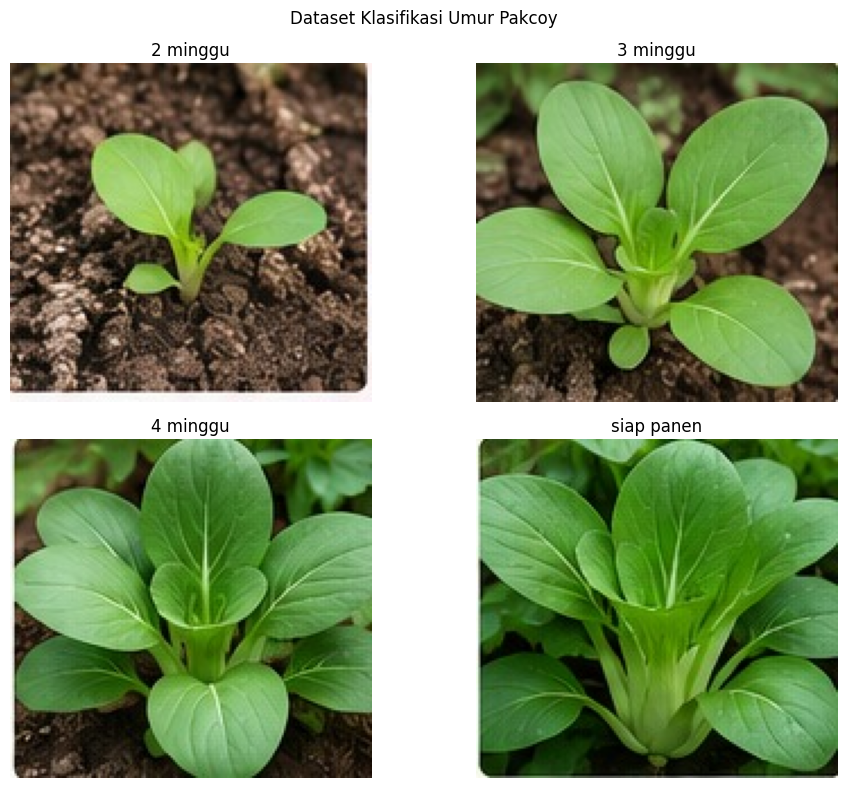

In [ ]:

# BAGIAN 2 — VISUALISASI DATASET

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, nama_kelas in enumerate(CLASS_NAMES):
    folder = DATASET_PATH / nama_kelas

    daftar = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    axes[i].set_title(nama_kelas.replace("_", " "))

    if daftar:
        img = tf.keras.utils.load_img(daftar[0])
        axes[i].imshow(img)
        axes[i].axis("off")
    else:
        axes[i].text(
            0.5, 0.5, "Belum ada gambar",
            ha="center", va="center"
        )
        axes[i].axis("off")

plt.suptitle("Dataset Klasifikasi Umur Pakcoy")
plt.tight_layout()
plt.show()


In [ ]:

# BAGIAN 3 — MEMUAT DATASET

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.25,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.25,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Gunakan urutan kelas dari TensorFlow agar label tidak tertukar
CLASS_NAMES = train_ds.class_names

print("\nUrutan label model:")
for i, nama in enumerate(CLASS_NAMES):
    print(i, "=", nama)

# Mempercepat proses input
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("\nDataset siap digunakan.")


Found 32 files belonging to 4 classes.
Using 24 files for training.
Found 32 files belonging to 4 classes.
Using 8 files for validation.

Urutan label model:
0 = 2_minggu
1 = 3_minggu
2 = 4_minggu
3 = siap_panen

Dataset siap digunakan.


In [ ]:

# BAGIAN 4 — MEMBANGUN MODEL

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Gunakan bobot pralatih ImageNet
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Bekukan lapisan dasar saat pelatihan awal
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Normalisasi sesuai rentang input MobileNetV2
    layers.Rescaling(1.0 / 127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# BAGIAN 5 — PELATIHAN MODEL

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)

print("\nPelatihan demo selesai.")


Epoch 1/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 535ms/step - accuracy: 0.1250 - loss: 1.5196 - val_accuracy: 0.3750 - val_loss: 1.1650
Epoch 2/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 216ms/step - accuracy: 0.5833 - loss: 0.9894 - val_accuracy: 0.6250 - val_loss: 0.9174
Epoch 3/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 289ms/step - accuracy: 0.4583 - loss: 0.8941 - val_accuracy: 0.6250 - val_loss: 0.7903
Epoch 4/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 276ms/step - accuracy: 0.8333 - loss: 0.6231 - val_accuracy: 0.8750 - val_loss: 0.6360
Epoch 5/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 200ms/step - accuracy: 0.8333 - loss: 0.5540 - val_accuracy: 0.8750 - val_loss: 0.5321

Pelatihan demo selesai.


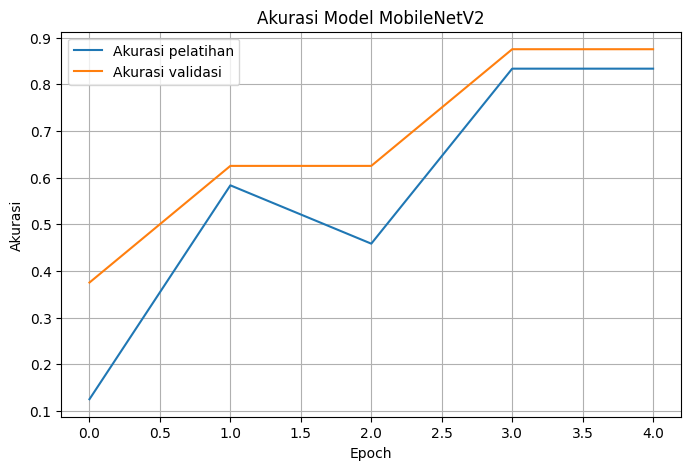

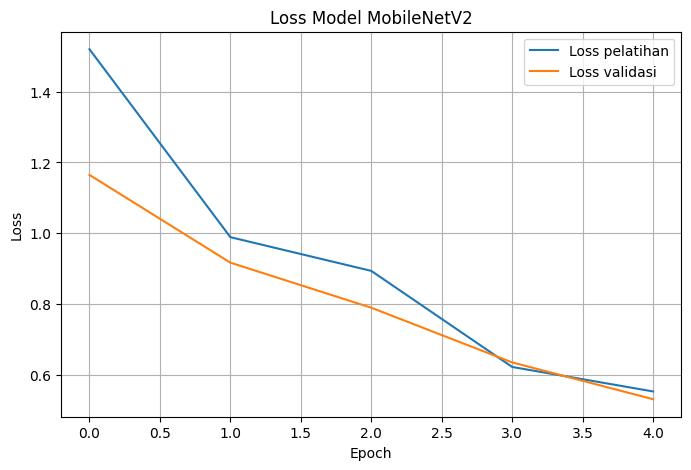

In [ ]:

# BAGIAN 6 — GRAFIK PELATIHAN

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Akurasi pelatihan")
plt.plot(history.history["val_accuracy"], label="Akurasi validasi")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.title("Akurasi Model MobileNetV2")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Loss pelatihan")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Model MobileNetV2")
plt.legend()
plt.grid(True)
plt.show()


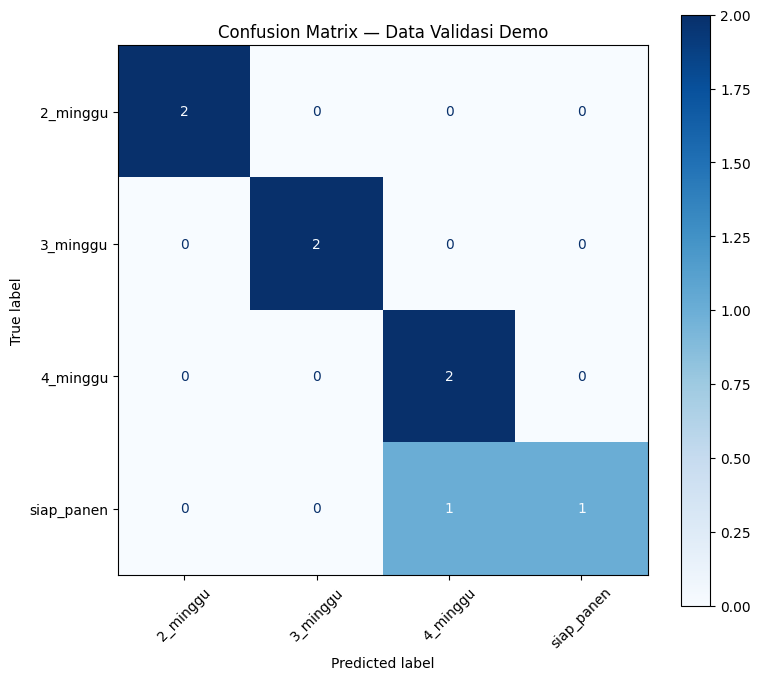


Laporan klasifikasi demo:
              precision    recall  f1-score   support

    2_minggu       1.00      1.00      1.00         2
    3_minggu       1.00      1.00      1.00         2
    4_minggu       0.67      1.00      0.80         2
  siap_panen       1.00      0.50      0.67         2

    accuracy                           0.88         8
   macro avg       0.92      0.88      0.87         8
weighted avg       0.92      0.88      0.87         8



In [ ]:

# BAGIAN 7 — EVALUASI DEMO

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy().tolist())
    y_pred.extend(predictions.tolist())

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(8, 7))
display_cm.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix — Data Validasi Demo")
plt.tight_layout()
plt.show()

print("\nLaporan klasifikasi demo:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))


In [ ]:

# Memeriksa isi ZIP dataset dan mengekstraknya

from pathlib import Path
import zipfile

zip_path = Path("/content/dataset_pakcoy_demo.zip")
folder_tujuan = Path("/content/dataset_pakcoy_demo")

if not zip_path.exists():
    print("File ZIP tidak ditemukan. Silakan unggah ZIP kembali.")
else:
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(folder_tujuan)

    print("Dataset berhasil diekstrak!")
    print("Lokasi:", folder_tujuan)

    for folder in sorted(folder_tujuan.iterdir()):
        if folder.is_dir():
            jumlah = sum(
                1 for p in folder.rglob("*")
                if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
            )
            print(folder.name, ":", jumlah, "gambar")


Dataset berhasil diekstrak!
Lokasi: /content/dataset_pakcoy_demo
2_minggu : 8 gambar
3_minggu : 8 gambar
4_minggu : 8 gambar
dataset_pakcoy_demo : 32 gambar
siap_panen : 8 gambar


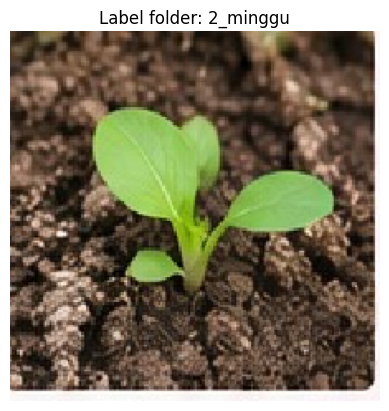

File: pakcoy_08.jpg
Label folder: 2_minggu
Prediksi demo: 2_minggu
Skor model: 91.10%


In [ ]:

# Prediksi satu gambar dari dataset demo

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

folder_dataset = Path("/content/dataset_pakcoy_demo")
kelas = ["2_minggu", "3_minggu", "4_minggu", "siap_panen"]

gambar_tersedia = []

for nama_kelas in kelas:
    folder = folder_dataset / nama_kelas

    if folder.exists():
        for p in folder.rglob("*"):
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
                gambar_tersedia.append((p, nama_kelas))

if gambar_tersedia:
    path_gambar, label_folder = gambar_tersedia[0]

    gambar = tf.keras.utils.load_img(
        path_gambar,
        target_size=(224, 224)
    )

    array_gambar = tf.keras.utils.img_to_array(gambar)
    array_gambar = np.expand_dims(array_gambar, axis=0)

    # Menggunakan model yang sudah dilatih sebelumnya
    model_dipakai = (
        model_tersimpan if "model_tersimpan" in globals()
        else model
    )

    hasil = model_dipakai.predict(array_gambar, verbose=0)[0]
    prediksi = kelas[int(np.argmax(hasil))]

    plt.imshow(gambar)
    plt.axis("off")
    plt.title("Label folder: " + label_folder)
    plt.show()

    print("File:", path_gambar.name)
    print("Label folder:", label_folder)
    print("Prediksi demo:", prediksi)
    print("Skor model:", f"{np.max(hasil)*100:.2f}%")
else:
    print("Belum ditemukan gambar di folder dataset.")


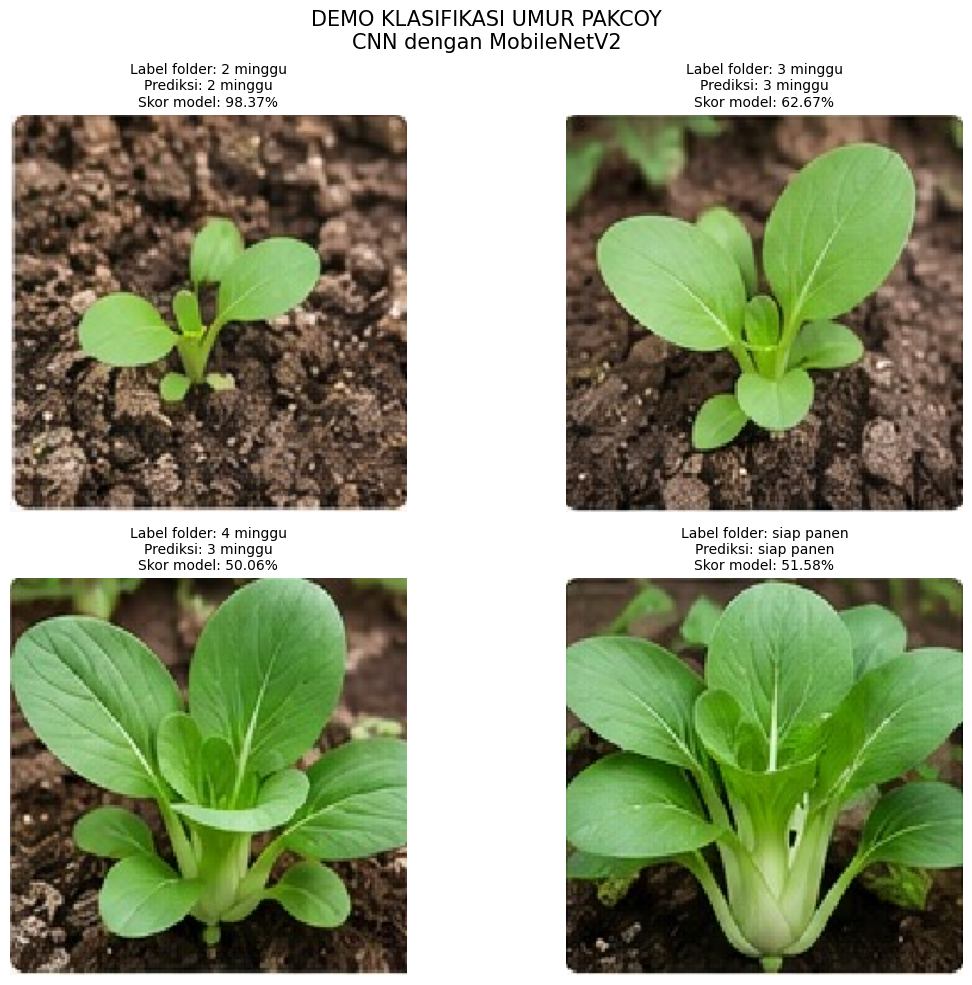

In [ ]:

# BAGIAN LANJUTAN — PREDIKSI 4 KELAS PAKCOY

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Folder gambar demo
folder_dataset = Path("/content/dataset_pakcoy_demo")

# Urutan empat kelas
kelas_pakcoy = [
    "2_minggu",
    "3_minggu",
    "4_minggu",
    "siap_panen"
]

# Menggunakan model yang sudah dilatih
if "model_tersimpan" in globals():
    model_uji = model_tersimpan
elif "model" in globals():
    model_uji = model
else:
    raise ValueError(
        "Model belum tersedia. Jalankan bagian pelatihan model dahulu."
    )

# Menyiapkan tampilan 4 gambar
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, nama_kelas in enumerate(kelas_pakcoy):
    folder = folder_dataset / nama_kelas

    daftar_gambar = []
    if folder.exists():
        for file in folder.iterdir():
            if file.suffix.lower() in [
                ".jpg", ".jpeg", ".png", ".webp"
            ]:
                daftar_gambar.append(file)

    if not daftar_gambar:
        axes[i].set_title(nama_kelas + " — gambar belum tersedia")
        axes[i].axis("off")
        continue

    # Ambil satu gambar dari setiap kelas
    path_gambar = sorted(daftar_gambar)[0]

    gambar = tf.keras.utils.load_img(
        path_gambar,
        target_size=(224, 224)
    )

    array_gambar = tf.keras.utils.img_to_array(gambar)
    array_gambar = np.expand_dims(array_gambar, axis=0)

    # Melakukan prediksi
    skor_semua_kelas = model_uji.predict(
        array_gambar, verbose=0
    )[0]

    indeks = int(np.argmax(skor_semua_kelas))
    hasil_prediksi = kelas_pakcoy[indeks]
    skor = float(skor_semua_kelas[indeks]) * 100

    axes[i].imshow(gambar)
    axes[i].set_title(
        f"Label folder: {nama_kelas.replace('_', ' ')}\n"
        f"Prediksi: {hasil_prediksi.replace('_', ' ')}\n"
        f"Skor model: {skor:.2f}%",
        fontsize=10
    )
    axes[i].axis("off")

plt.suptitle(
    "DEMO KLASIFIKASI UMUR PAKCOY\n"
    "CNN dengan MobileNetV2",
    fontsize=15
)
plt.tight_layout()
plt.show()
